# 2.5 Gridded data: coordinates, units and the file on disk

🖥️ [**Lecture slides — Session 06 (Mon Oct 12)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec06_sampling_resampling.html)

Climate models, reanalyses, ocean products and satellite images all arrive as grids: arrays of numbers whose position stands for a time, a latitude, a longitude or a depth. A grid fails quietly. Pick the wrong cell, forget a unit conversion, or read a different version of the file, and you still get a plausible number. Nothing raises an error.

This notebook works with one real grid, an atmospheric reanalysis over North America, and asks what a single value in it means and how each processing step can change that meaning. An agent can write every line of code here in seconds. What it cannot do for you is decide which cell is Seattle, whether the numbers are still in kelvin, or whether the file is the one you think you downloaded. Those decisions are the subject of this notebook.

**You should be able to:**

1. Describe one value in the grid: the variable, the model level it sits on, the grid spacing, the time in UTC, and how much of it comes from the model rather than from observations.
2. Estimate the memory a grid needs from its shape and data type before loading it, and read how it is packed on disk.
3. Select a location by coordinate with a stated tolerance, and catch the two traps that return an empty or wrong selection without an error.
4. Convert units on a copy whose metadata still describe the numbers, and show that a rerun gives the same result.
5. Give a failing check table to an agent, verify its fix, and log the exchange.

| Part | Question | Mode | Minutes |
|---|---|---|---|
| 0 | What does "Seattle's temperature" in this file stand for? | by hand | 2 |
| 1 | Which file is this, and will it fit in memory? | by hand | 6 |
| 2 | Is this a thermometer reading at 4 pm? | by hand | 8 |
| 3 | Which cell is Seattle? | by hand, then assistant allowed | 10 |
| 4 | Do the metadata still describe the numbers? | assistant allowed | 7 |
| 5 | Is the agent's Seattle series from the right cell, in °C? | agent, then verify | 15 |
| Data card | Fill the grid fields | by hand | 10, after class |
| Extensions | Area weighting, the annual cycle, what a tensor forgets | assistant allowed (569 required) | self-paced |

**Two calls to be able to read in any agent's code:** `.sel(..., method="nearest", tolerance=...)`, which decides which cell you get, and `.encoding`, which says how the numbers are stored on disk. You do not need to memorize the rest of the syntax; you need to check what it returns.

## The dataset

**NCEP/NCAR Reanalysis 1, air temperature at the lowest model level, every 6 hours, 2013 to 2014, over North America.**

🖥️ Model & simulation · 🌤️ Atmosphere · 🌡️ Atmospheric & climate science

A reanalysis runs one fixed weather-forecast model forward in time and pulls it toward the observations available at each step: radiosondes, aircraft, satellites, surface stations, ships. The result is a complete, gridded estimate of the atmosphere, even where nobody measured. This grid holds air temperature on the model's lowest level (sigma = 0.995, meaning a pressure 99.5% of the surface pressure), four times a day, on a 2.5° latitude-longitude grid.

- **Provider:** NOAA Physical Sciences Laboratory (PSL), [NCEP/NCAR Reanalysis 1](https://psl.noaa.gov/data/gridded/data.ncep.reanalysis.html).
- **Reference:** Kalnay, E., et al. (1996). The NCEP/NCAR 40-year reanalysis project. *Bulletin of the American Meteorological Society*, 77, 437–471. [doi:10.1175/1520-0477(1996)077<0437:TNYRP>2.0.CO;2](https://doi.org/10.1175/1520-0477(1996)077%3C0437:TNYRP%3E2.0.CO;2)
- **This copy:** a two-year subset distributed by the Xarray project in [pydata/xarray-data](https://github.com/pydata/xarray-data), pinned below to one commit and one checksum.

Two statements from Kalnay et al. (1996) decide how you may use these numbers. The model "has 5 levels in the boundary layer", and "the lowest model level is about 5 hPa from the surface". And "temperature at the lowest sigma level" is a **class B** variable: "although there are observational data that directly affect the value of the variable, the model also has a very strong influence on the analysis value". Keep both in mind when you compare this grid with a thermometer.

In [1]:
import hashlib
import json
import os
import stat
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import xarray as xr

pooch.get_logger().setLevel("WARNING")
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)


def run_checks(checks):
    """Run named checks and return a table. A failing check is reported, never raised.

    checks: list of (name, expected, observed, passed) tuples.
    """
    table = pd.DataFrame(checks, columns=["check", "expected", "observed", "pass"])
    n_fail = int((~table["pass"]).sum())
    print(f"{len(table) - n_fail} of {len(table)} checks pass")
    return table

## 0. Predict first

```{admonition} 🔒 By hand
:class: attention
Assistant closed for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

Before opening the file, write down in a markdown cell what you expect "Seattle's air temperature" in this grid to stand for:

- At what height above the ground?
- Over what area: a point, a city, or something larger?
- At what local times of day?
- Measured by a thermometer, or estimated by a model?

You will check each answer against the file and the provider in parts 1 and 2.

## 1. Which file is this, and will it fit in memory?

A grid you download today may not be the grid someone else downloads next year: providers reprocess, mirrors change, and files get edited by hand. The first habit is to fix which bytes you used. We download one pinned file, check its SHA-256 checksum against the value recorded here, and then make the local copy **read-only**, so that no later cell (and no agent) can overwrite the raw data by accident. Everything derived from it gets a new name.

Be precise about what the checksum proves. It was recorded from the Xarray project's copy at commit `2baf0c2`, a two-year North America subset. A match proves you hold the same bytes as that pinned copy. It does not prove the copy matches what NOAA PSL distributes, which is a set of global yearly files; the file's own title, "4x daily NMC reanalysis (1948)", shows it was repackaged. A subset made by someone else is a version of its own, and your data card should name it.

```{admonition} 🔒 By hand
:class: attention
Assistant closed for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

The grid has 2,920 time steps × 25 latitudes × 53 longitudes. Before running the next cells, estimate by hand how many megabytes it takes in memory as 64-bit floats (8 bytes per value). Write your number down.

In [2]:
RAW_URL = ("https://github.com/pydata/xarray-data/raw/"
           "2baf0c22d9671a2058415f17e71b3fe06239a3dd/air_temperature.nc")
RAW_SHA256 = "c606b89c35970a2983b914b76df4adbb409003ef34aa7cfd7f582e41f307482b"

raw_path = Path(pooch.retrieve(
    url=RAW_URL,
    known_hash=f"sha256:{RAW_SHA256}",   # pooch refuses a file whose bytes differ
    fname="air_temperature_raw.nc",
    path=DATA_DIR,
    downloader=pooch.HTTPDownloader(timeout=120),
))
os.chmod(raw_path, stat.S_IRUSR | stat.S_IRGRP | stat.S_IROTH)   # read-only from here on

print("file:     ", raw_path.relative_to(Path.cwd()) if raw_path.is_relative_to(Path.cwd()) else raw_path.name)
print("sha256:   ", pooch.file_hash(raw_path))
print("writable: ", os.access(raw_path, os.W_OK))
print(f"on disk:   {raw_path.stat().st_size / 1e6:.1f} MB")

file:      data/air_temperature_raw.nc
sha256:    c606b89c35970a2983b914b76df4adbb409003ef34aa7cfd7f582e41f307482b
writable:  False
on disk:   7.8 MB


In [3]:
ds = xr.open_dataset(raw_path)          # lazy: reads metadata now, values only when needed
air = ds["air"]

print("dimensions:", dict(air.sizes))
print("in memory as", air.dtype, f"= {air.size * air.dtype.itemsize / 1e6:.1f} MB")
print("on disk as  ", air.encoding["dtype"], "with scale_factor", air.encoding.get("scale_factor"))
print(f"for scale: a global hourly 0.25 degree grid, one variable, one year, as float64 = "
      f"{8760 * 721 * 1440 * 8 / 1e9:.0f} GB")

dimensions: {'time': 2920, 'lat': 25, 'lon': 53}
in memory as float64 = 31.0 MB
on disk as   int16 with scale_factor 0.01
for scale: a global hourly 0.25 degree grid, one variable, one year, as float64 = 73 GB


The file stores each temperature as a 16-bit integer counting hundredths of a kelvin (`scale_factor` 0.01). That packing sets the precision of every number you will read: 0.01 K, no better. On loading, Xarray multiplies by the scale factor and holds the result as 64-bit floats, which is why the grid is four times larger in memory than on disk. Compare the printed size with your estimate.

The same arithmetic tells you, before you download anything, whether a grid fits on your laptop. The last line above does it for a global hourly grid at 0.25° (8,760 × 721 × 1,440 values for one variable and one year): far more than a laptop's memory. That is the scale where Chapter 5's chunked, lazy formats become necessary.

## 2. Is this a thermometer reading at 4 pm?

```{admonition} 🔒 By hand
:class: attention
Assistant closed for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

Read the file's own description of the variable, then compare it with the provider's documentation quoted above.

In [4]:
print(json.dumps({k: str(v) for k, v in ds.attrs.items()}, indent=1))
print(json.dumps({k: str(v) for k, v in air.attrs.items()}, indent=1))

{
 "Conventions": "COARDS",
 "title": "4x daily NMC reanalysis (1948)",
 "description": "Data is from NMC initialized reanalysis\n(4x/day).  These are the 0.9950 sigma level values.",
 "platform": "Model",
 "references": "http://www.esrl.noaa.gov/psd/data/gridded/data.ncep.reanalysis.html"
}
{
 "long_name": "4xDaily Air temperature at sigma level 995",
 "units": "degK",
 "precision": "2",
 "GRIB_id": "11",
 "GRIB_name": "TMP",
 "var_desc": "Air temperature",
 "dataset": "NMC Reanalysis",
 "level_desc": "Surface",
 "statistic": "Individual Obs",
 "parent_stat": "Other",
 "actual_range": "[185.16 322.1 ]"
}


In [5]:
dlat = np.unique(np.diff(ds.lat.values))
dlon = np.unique(np.diff(ds.lon.values))
dt_hours = np.unique(np.diff(ds.time.values).astype("timedelta64[h]").astype(int))
print("latitude step (deg): ", dlat, " -> latitude runs", "north to south" if dlat[0] < 0 else "south to north")
print("longitude step (deg):", dlon, " longitude range:", float(ds.lon.min()), "to", float(ds.lon.max()))
print("time step (hours):   ", dt_hours, " hours of day (UTC):", sorted(set(ds.time.dt.hour.values.tolist())))
print(f"one 2.5 x 2.5 degree cell at 47.5 N spans about {2.5 * 111.2:.0f} km north-south "
      f"and {2.5 * 111.2 * np.cos(np.deg2rad(47.5)):.0f} km east-west")

latitude step (deg):  [-2.5]  -> latitude runs north to south


longitude step (deg): [2.5]  longitude range: 200.0 to 330.0
time step (hours):    [6]  hours of day (UTC): [0, 6, 12, 18]
one 2.5 x 2.5 degree cell at 47.5 N spans about 278 km north-south and 188 km east-west


In [6]:
# How high is "about 5 hPa from the surface"? Hydrostatic balance: dz = (R T / g) dp / p
R_dry, g = 287.0, 9.81          # J kg-1 K-1, m s-2
T, p, dp = 283.0, 1000.0, 5.0   # a mild surface temperature (K), surface pressure and layer depth (hPa)
print(f"5 hPa above a 1000 hPa surface at {T - 273.15:.0f} C is about {R_dry * T / g * dp / p:.0f} m")

5 hPa above a 1000 hPa surface at 10 C is about 41 m


Three things in the file's own metadata do not match the provider's description, and each one matters:

| The file says | What it is | Why it matters |
|---|---|---|
| `level_desc: Surface` | The lowest model level, sigma 0.995, about 40 m above the **model's** ground (computed in the code cell above; Kalnay et al. 1996, Table 1, puts sigma 0.995 at the middle of an 80 m thick lowest layer) | Not the 2 m height of a weather-station thermometer |
| `statistic: Individual Obs` | An analysis: a model state pulled toward observations, class B in Kalnay et al. (1996) | Observations affect the value directly, but "the model also has a very strong influence" on it: treat it as an estimate, not a measurement |
| `units: degK` | Kelvin. `degK` is a valid alias in UDUNITS, the unit library behind the COARDS and CF (Climate and Forecast) conventions; the CF standard names write the unit as `K` | A check that compares the units string with `"K"` fails on this file; a unit-aware parser accepts it |

Two more facts you computed above:

- **Time.** The four daily values are instantaneous states at 00, 06, 12 and 18 UTC. In Seattle (UTC−8 in winter, UTC−7 in summer) that is late afternoon, evening, early morning and late morning. The 00 UTC value lands near the afternoon maximum and the 12 UTC value near the early-morning minimum, but neither is the daily extreme, so a daily mean of four values is not the same as the mean of a station's daily maximum and minimum.
- **Area.** Grid points are 2.5° apart, about 280 km × 190 km at Seattle's latitude (computed above). Each value is interpolated to its grid point from the model's native grid (192 × 94 points, Kalnay et al. 1996); it is not an average over the box. The model's terrain is smoothed at its T62 spectral resolution (62 waves around a latitude circle, about 210 km), so the Olympic Mountains, the Cascades and Puget Sound are blurred into a few grid points.

Go back to your prediction from part 0 and correct it.

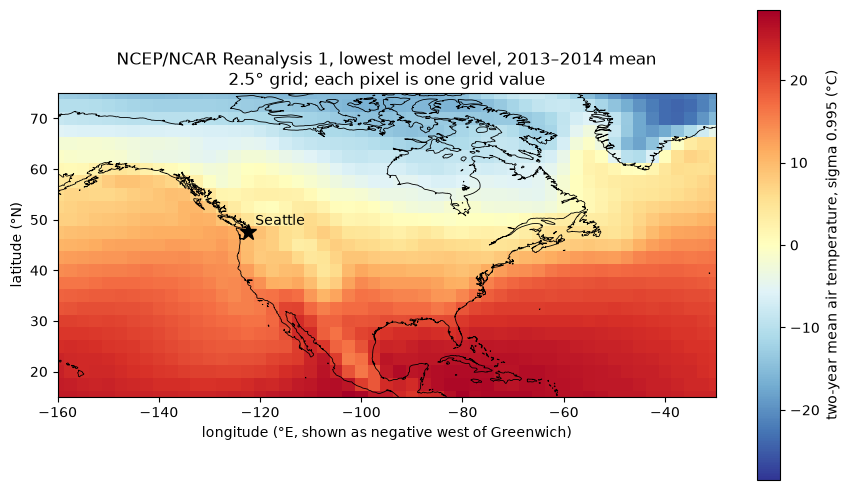

In [7]:
coast_zip = pooch.retrieve(
    url="https://naciscdn.org/naturalearth/50m/physical/ne_50m_coastline.zip",
    known_hash="sha256:640f805509b822f57f4840a2e18d9ff2412cf1cf6976124701c2789436166fde",
    fname="ne_50m_coastline.zip",
    path=DATA_DIR,
)
coast = gpd.read_file(coast_zip)

SEATTLE = {"lat": 47.61, "lon_east": 360 - 122.33}   # degrees north, degrees east (0-360)
mean_c = air.mean("time") - 273.15                    # two-year mean, converted for display only

fig, ax = plt.subplots(figsize=(9, 5))
mean_c.assign_coords(lon=mean_c.lon - 360).plot(ax=ax, cmap="RdYlBu_r",
                                                cbar_kwargs={"label": "two-year mean air temperature, sigma 0.995 (°C)"})
coast.plot(ax=ax, color="k", linewidth=0.6)
ax.plot(SEATTLE["lon_east"] - 360, SEATTLE["lat"], marker="*", color="k", markersize=12)
ax.annotate("Seattle", (SEATTLE["lon_east"] - 360, SEATTLE["lat"]), xytext=(5, 5), textcoords="offset points")
ax.set_xlim(-160, -30); ax.set_ylim(15, 75)
ax.set_xlabel("longitude (°E, shown as negative west of Greenwich)"); ax.set_ylabel("latitude (°N)")
ax.set_title("NCEP/NCAR Reanalysis 1, lowest model level, 2013–2014 mean\n2.5° grid; each pixel is one grid value")
plt.tight_layout(); plt.show()

Notice the blocks: each colored square is one grid value. Coastlines are drawn at a far finer resolution than the data, which makes the grid look more precise than it is.

**For your data card** (template in [2.13](2.13_MLready_data.ipynb); the final project in [2.20](2.20_Final_Project_Assignement.md) requires one). Fill these fields after part 5 or after class, in a markdown cell; it takes about 10 minutes. They are the fields a gridded dataset needs beyond the ones a table needs:

| Field | This grid |
|---|---|
| Variable and level | |
| Grid spacing and extent | |
| Coordinate convention (longitude range, latitude order) | |
| Time: sampling, instantaneous or averaged, time zone | |
| Units in the file, and in your derived product | |
| Packing on disk and resulting precision | |
| Observation versus model (Kalnay class) | |
| Provider, the copy you used and its version, checksum | |

## 3. Which cell is Seattle?

```{admonition} 🔒 By hand
:class: attention
Assistant closed for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

A labeled array lets you select by coordinate value instead of by position. That removes one class of error (counting rows) and opens two others, because a coordinate selection can return the wrong cell without any warning. We first practise on a tiny test grid whose values encode their own position, so you can read the answer directly.

Before running the next three code cells, write two predictions in a markdown cell: (a) what `test.sel(lat=slice(45, 50))` returns on a grid stored north to south; (b) which longitude `method="nearest"` returns when you ask a grid stored as −180 to 180° for longitude 237.7.

In [8]:
# A 3 x 3 test grid laid out like the reanalysis: latitude from north to south, longitude in degrees east.
# Each value encodes its own coordinates: value = 1000 * lat + lon.
test_lat = np.array([50.0, 47.5, 45.0])
test_lon = np.array([235.0, 237.5, 240.0])
test = xr.DataArray(1000 * test_lat[:, None] + test_lon[None, :],
                    coords={"lat": test_lat, "lon": test_lon}, dims=("lat", "lon"))

print("position [1, 1]:              ", float(test.isel(lat=1, lon=1)))
print("label lat=47.5, lon=237.5:    ", float(test.sel(lat=47.5, lon=237.5)))
print("slice lat 45 to 50 (ascending):", test.sel(lat=slice(45, 50)).lat.values, "  <- empty")
print("slice lat 50 to 45 (as stored):", test.sel(lat=slice(50, 45)).lat.values)

position [1, 1]:               47737.5
label lat=47.5, lon=237.5:     47737.5
slice lat 45 to 50 (ascending): []   <- empty
slice lat 50 to 45 (as stored): [50.  47.5 45. ]


**Trap 1, latitude order.** The reanalysis stores latitude from north to south, like the test grid. A slice written in the usual south-to-north order returns an empty array, and any mean taken over it is `nan` or an error several cells later. The same happens on the real grid:

In [9]:
print("cells with 40 <= lat <= 50, slice(40, 50):", ds.sel(lat=slice(40, 50)).lat.size)
print("cells with 40 <= lat <= 50, slice(50, 40):", ds.sel(lat=slice(50, 40)).lat.size)

cells with 40 <= lat <= 50, slice(40, 50): 0
cells with 40 <= lat <= 50, slice(50, 40): 5


**Trap 2, longitude convention.** This file uses degrees east from 0 to 360; Seattle is at 237.7° E. Many datasets use −180 to 180, where Seattle is −122.3°. A common processing step converts one convention to the other. Below, a copy of the grid is converted, and then queried with the 0-360 longitude:

In [10]:
ds_w = ds.copy(deep=True)
ds_w.coords["lon"] = ds_w.lon - 360          # now -160 ... -30

for name, grid in [("original (0-360)", ds), ("converted (-180-180)", ds_w)]:
    cell = grid.sel(lat=SEATTLE["lat"], lon=SEATTLE["lon_east"], method="nearest")
    print(f"{name:22s} nearest to lon 237.7 -> lat {float(cell.lat):5.1f}, lon {float(cell.lon):6.1f}")

try:
    ds_w.sel(lon=SEATTLE["lon_east"], method="nearest", tolerance=1.25)
except KeyError:
    print("with tolerance=1.25 degrees: KeyError, no cell within half a grid step")

original (0-360)       nearest to lon 237.7 -> lat  47.5, lon  237.5
converted (-180-180)   nearest to lon 237.7 -> lat  47.5, lon  -30.0
with tolerance=1.25 degrees: KeyError, no cell within half a grid step


On the converted copy, `method="nearest"` returns longitude −30°, the eastern edge of the grid in the Atlantic, about 6,500 km from Seattle, and raises nothing. "Nearest" always finds something. A tolerance of half a grid step (1.25°) turns the silent error into a `KeyError`. The check tables below report every longitude in degrees east, 0 to 360, whatever the grid stores, so this cell appears there as 330.00 E.

Two rules follow, and both are easy to check in anyone's code, including an agent's:

1. Every nearest-neighbor selection carries a tolerance of half the grid spacing.
2. After every selection, print or test the coordinates you got back, not only the values.

The check table below states these rules as tests, for a function that selects Seattle correctly:

In [11]:
HALF_STEP = 1.25   # degrees, half of the 2.5 degree grid spacing


def seattle_cell(grid):
    """Select the grid cell containing Seattle, whatever the longitude convention."""
    lon = SEATTLE["lon_east"] if float(grid.lon.max()) > 180 else SEATTLE["lon_east"] - 360
    return grid.sel(lat=SEATTLE["lat"], lon=lon, method="nearest", tolerance=HALF_STEP)


def lon_east(x):
    return float(x) % 360


checks = []
for name, grid in [("original", ds), ("converted", ds_w)]:
    cell = seattle_cell(grid)
    checks.append((f"{name}: latitude within half a step", f"|lat - 47.61| <= {HALF_STEP}",
                   f"{float(cell.lat):.2f}", abs(float(cell.lat) - SEATTLE["lat"]) <= HALF_STEP))
    checks.append((f"{name}: longitude within half a step", f"|lon - 237.67| <= {HALF_STEP}",
                   f"{lon_east(cell.lon):.2f} E", abs(lon_east(cell.lon) - SEATTLE["lon_east"]) <= HALF_STEP))
run_checks(checks)

4 of 4 checks pass


,check,expected,observed,pass
0,original: latitude within half a step,|lat - 47.61| <= 1.25,47.50,True
1,original: longitude within half a step,|lon - 237.67| <= 1.25,237.50 E,True
2,converted: latitude within half a step,|lat - 47.61| <= 1.25,47.50,True
3,converted: longitude within half a step,|lon - 237.67| <= 1.25,237.50 E,True


**Your turn.** By hand, write down the tolerance you will use and the grid point you expect. Then, with an assistant if you like, select the cell for Fairbanks, Alaska (64.84° N, 147.72° W) on both `ds` and `ds_w`, print the coordinates you get back, and add two rows for it to the check table. Last, select the band from 40° N to 50° N on `ds` and confirm it holds 5 latitudes.

## 4. Do the metadata still describe the numbers?

```{admonition} 🤝 Assistant allowed
:class: tip
Use your assistant if you want. Verify every line and disclose the use in your submission ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

Converting kelvin to Celsius is one subtraction. The error is in what is left behind: an attribute that still says `degK`, an `actual_range` still in kelvin, and, worst, an original grid that was changed in place because the conversion wrote into the same memory. Three habits prevent this:

- convert on a **copy**, never on the raw grid;
- update every attribute that describes the values, and record what was done in a `history` attribute;
- **fingerprint** the result, so that a rerun can show it produced exactly the same numbers and metadata.

The fingerprint below hashes the values and the attributes. We hash the numbers and attributes rather than a written file, because two libraries, or two versions of one library, can write identical numbers into files whose bytes differ.

In [12]:
def fingerprint(da):
    """SHA-256 of an array's values and attributes: same numbers and metadata give the same hash."""
    h = hashlib.sha256(np.ascontiguousarray(da.values).tobytes())
    h.update(json.dumps({k: str(v) for k, v in sorted(da.attrs.items())}).encode())
    return h.hexdigest()[:16]


def to_celsius(da):
    """Return a new DataArray in degrees Celsius; the input is not modified."""
    if da.attrs.get("units") not in ("K", "degK"):
        raise ValueError(f"expected kelvin, got units={da.attrs.get('units')!r}")
    out = da - 273.15                       # a new array: '-' never writes into da
    out.attrs = dict(da.attrs)
    out.attrs["units"] = "degC"
    out.attrs["actual_range"] = [round(float(out.min()), 2), round(float(out.max()), 2)]
    out.attrs["history"] = "converted from K to degC (subtracted 273.15) in 2.5_Arrays.ipynb"
    return out


raw_before = fingerprint(air)
air_c = to_celsius(air)
run_checks([
    ("raw grid unchanged", raw_before, fingerprint(air), fingerprint(air) == raw_before),
    ("units attribute updated", "degC", air_c.attrs["units"], air_c.attrs["units"] == "degC"),
    ("actual_range matches the data", "min/max of values", str(air_c.attrs["actual_range"]),
     np.allclose(air_c.attrs["actual_range"], [float(air_c.min()), float(air_c.max())], atol=0.01)),
    ("rerun gives the same result", fingerprint(air_c), fingerprint(to_celsius(air)),
     fingerprint(to_celsius(air)) == fingerprint(air_c)),
])

4 of 4 checks pass


,check,expected,observed,pass
0,raw grid unchanged,9b0cb043ad7f2d10,9b0cb043ad7f2d10,True
1,units attribute updated,degC,degC,True
2,actual_range matches the data,min/max of values,"[-52.15, 44.25]",True
3,rerun gives the same result,07a310c80a7107b0,07a310c80a7107b0,True


**Your turn.** First, find the gap: delete the `history` line in `to_celsius`, rerun, and notice that no row fails. Write the check that would catch it, then restore the line. Second, write `to_kelvin(da)` under the same three habits (a copy, updated attributes with a `history` entry, a fingerprint), and add two checks: that `to_kelvin(to_celsius(air))` matches the raw values to within 0.01 K, the packing precision from part 1, and that `to_celsius(air_c)` raises an error instead of subtracting 273.15 a second time.

## 5. Is the agent's Seattle series from the right cell, in °C?

```{admonition} 🔍 Agent, then verify
:class: important
An agent writes this step. You accept it only after your checks pass, and you log the exchange in `AI_logs/` ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

The function below extracts Seattle's temperature series in °C. It was **written by the instructor to reproduce faults that coding agents commonly make**; it is not a real agent transcript. It looks reasonable and it runs without error on both grids. Your job is to decide whether to accept it.

In [13]:
def seattle_series_agent(ds):
    """Return Seattle's air temperature time series in degrees Celsius."""
    air = ds["air"]
    air -= 273.15                                   # convert to Celsius
    return air.sel(lat=47.65, lon=237.7, method="nearest")

In [14]:
def check_seattle_series(func, grid, label):
    """Checks a Seattle-series function must pass, run on a private copy of `grid`."""
    grid = grid.copy(deep=True)
    before = fingerprint(grid["air"])
    out = func(grid)
    after = fingerprint(grid["air"])
    lat, lon = float(out.lat), lon_east(out.lon)
    winter = float(out.sel(time=out.time.dt.month.isin([12, 1, 2])).mean())
    summer = float(out.sel(time=out.time.dt.month.isin([6, 7, 8])).mean())
    return [
        (f"{label}: cell is Seattle's (latitude)", "within 1.25 of 47.61", f"{lat:.2f}", abs(lat - SEATTLE["lat"]) <= HALF_STEP),
        (f"{label}: cell is Seattle's (longitude)", "within 1.25 of 237.67 E", f"{lon:.2f} E", abs(lon - SEATTLE["lon_east"]) <= HALF_STEP),
        (f"{label}: input grid not modified", "same fingerprint", "same" if after == before else "changed", after == before),
        (f"{label}: units attribute says Celsius", "degC", str(out.attrs.get("units")), out.attrs.get("units") == "degC"),
        (f"{label}: winter mean is plausible for Seattle", "between -5 and 10 C", f"{winter:.1f}", -5 <= winter <= 10),
        (f"{label}: summer warmer than winter", "summer > winter", f"{summer:.1f} vs {winter:.1f}", summer > winter),
    ]


agent_table = run_checks(check_seattle_series(seattle_series_agent, ds, "original")
                         + check_seattle_series(seattle_series_agent, ds_w, "converted"))
print(agent_table[~agent_table["pass"]].to_string(index=False))   # the failing rows, as text you can paste
agent_table

7 of 12 checks pass


                                   check                expected observed  pass
       original: input grid not modified        same fingerprint  changed False
  original: units attribute says Celsius                    degC     degK False
converted: cell is Seattle's (longitude) within 1.25 of 237.67 E 330.00 E False
      converted: input grid not modified        same fingerprint  changed False
 converted: units attribute says Celsius                    degC     degK False


,check,expected,observed,pass
0,original: cell is Seattle's (latitude),within 1.25 of 47.61,47.50,True
1,original: cell is Seattle's (longitude),within 1.25 of 237.67 E,237.50 E,True
2,original: input grid not modified,same fingerprint,changed,False
3,original: units attribute says Celsius,degC,degK,False
4,original: winter mean is plausible for Seattle,between -5 and 10 C,3.0,True
5,original: summer warmer than winter,summer > winter,17.4 vs 3.0,True
6,converted: cell is Seattle's (latitude),within 1.25 of 47.61,47.50,True
7,converted: cell is Seattle's (longitude),within 1.25 of 237.67 E,330.00 E,False
8,converted: input grid not modified,same fingerprint,changed,False
9,converted: units attribute says Celsius,degC,degK,False


Before you prompt anything, write in a markdown cell which line of `seattle_series_agent` causes each failing row, and whether it is a wrong cell, a wrong unit label, or a side effect on the input. Notice also what passed: on the converted grid the function returns a cell in the mid-Atlantic (47.5° N, 30° W), and that cell passes both plausibility checks, the winter one by 0.1 °C (9.9 against an upper bound of 10). A believable winter mean and a seasonal cycle are not evidence of the right place; only the coordinate check catches it.

Then write one check of your own that the agent will not see, for example that the series has 2,920 values, or that its January 2013 mean equals the mean you compute yourself from the raw grid at 47.5° N, 237.5° E, minus 273.15. Then:

1. Give your agent three things: the function `seattle_series_agent`, the function `check_seattle_series` (so it sees what is tested), and the failing rows printed above. If you use a coding agent in your clone of the course book, point it at this notebook instead of pasting. A prompt that works: *"This function fails the checks below on two grids: `ds`, with longitude 0 to 360° E, and `ds_w`, with longitude −180 to 180°. Fix the function so that every check passes on both grids. Do not change the checks. Explain each change in one sentence."*
2. Paste the agent's function into the next cell, in place of the placeholder line, and run the checks again, including yours.
3. Read the agent's explanation against the table: did it fix the cause, or only make a check pass? A fix that deletes the longitude check, or that hard-codes −122.3 and so fails on the original grid, should be rejected.
4. Save the conversation in `AI_logs/` in your course repository, with your line-by-line diagnosis, your own check, and what you accepted, changed and verified ([1.9](../Chapter1-GettingStarted/1.9_workbench_setup_hw1.md)).

A reference fix is at the end of this part. Open it only after your log entry is saved.

In [15]:
# Replace this line with the agent's function, named seattle_series_fixed.
seattle_series_fixed = seattle_series_agent

run_checks(check_seattle_series(seattle_series_fixed, ds, "original")
           + check_seattle_series(seattle_series_fixed, ds_w, "converted"))

7 of 12 checks pass


,check,expected,observed,pass
0,original: cell is Seattle's (latitude),within 1.25 of 47.61,47.50,True
1,original: cell is Seattle's (longitude),within 1.25 of 237.67 E,237.50 E,True
2,original: input grid not modified,same fingerprint,changed,False
3,original: units attribute says Celsius,degC,degK,False
4,original: winter mean is plausible for Seattle,between -5 and 10 C,3.0,True
5,original: summer warmer than winter,summer > winter,17.4 vs 3.0,True
6,converted: cell is Seattle's (latitude),within 1.25 of 47.61,47.50,True
7,converted: cell is Seattle's (longitude),within 1.25 of 237.67 E,330.00 E,False
8,converted: input grid not modified,same fingerprint,changed,False
9,converted: units attribute says Celsius,degC,degK,False


A rule worth adding to your `AGENTS.md`, in the checkable form of HW1 Step 7: *"Select grid cells with `method="nearest"` only together with a tolerance of half the grid spacing, and print the coordinates of every selected cell."* Anyone can verify it by reading the code and the output.

### Reference fix (open after logging your own)

In [16]:
def seattle_series_reference(ds):
    """Return Seattle's air temperature series in degrees Celsius, without modifying ds."""
    return to_celsius(seattle_cell(ds)["air"])


run_checks(check_seattle_series(seattle_series_reference, ds, "original")
           + check_seattle_series(seattle_series_reference, ds_w, "converted"))

12 of 12 checks pass


,check,expected,observed,pass
0,original: cell is Seattle's (latitude),within 1.25 of 47.61,47.50,True
1,original: cell is Seattle's (longitude),within 1.25 of 237.67 E,237.50 E,True
2,original: input grid not modified,same fingerprint,same,True
3,original: units attribute says Celsius,degC,degC,True
4,original: winter mean is plausible for Seattle,between -5 and 10 C,3.0,True
5,original: summer warmer than winter,summer > winter,17.4 vs 3.0,True
6,converted: cell is Seattle's (latitude),within 1.25 of 47.61,47.50,True
7,converted: cell is Seattle's (longitude),within 1.25 of 237.67 E,237.50 E,True
8,converted: input grid not modified,same fingerprint,same,True
9,converted: units attribute says Celsius,degC,degC,True


## Extensions

```{admonition} 🤝 Assistant allowed
:class: tip
Use your assistant if you want. Verify every line and disclose the use in your submission ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

These are self-paced. Students in 569 do all three; students in 469 choose one.

### E1. Does an unweighted mean overstate the north?

On a latitude-longitude grid, cells shrink toward the pole in proportion to the cosine of latitude (the last line below gives the ratio between 75° N and 15° N). An unweighted mean over the grid gives the high-latitude cells too much weight.

In [17]:
weights = np.cos(np.deg2rad(air_c.lat))
unweighted = float(air_c.mean())
weighted = float(air_c.weighted(weights).mean())
print(f"two-year mean over the grid, unweighted:          {unweighted:6.2f} C")
print(f"two-year mean over the grid, area-weighted (cos): {weighted:6.2f} C")
print(f"area of a cell at 75 N relative to one at 15 N: {np.cos(np.deg2rad(75)) / np.cos(np.deg2rad(15)):.2f}")

two-year mean over the grid, unweighted:            8.11 C
two-year mean over the grid, area-weighted (cos):  12.36 C
area of a cell at 75 N relative to one at 15 N: 0.27


Write two sentences: which way the weighting moves the mean and why, and what else this box mixes (land and ocean, mountains and plains) that an area weight does not fix. If you average by season, note that a December-January-February winter spans two calendar years: in this grid, January and February 2013 have no December before them.

### E2. The annual cycle at Seattle

Fit a sinusoid with a period of 365.25 days to Seattle's series and report its mean, amplitude and the date of the maximum. Before fitting, write down what you expect for each from what you know about the Pacific Northwest climate.

mean 10.2 C, amplitude 8.1 C, warmest around 26 July


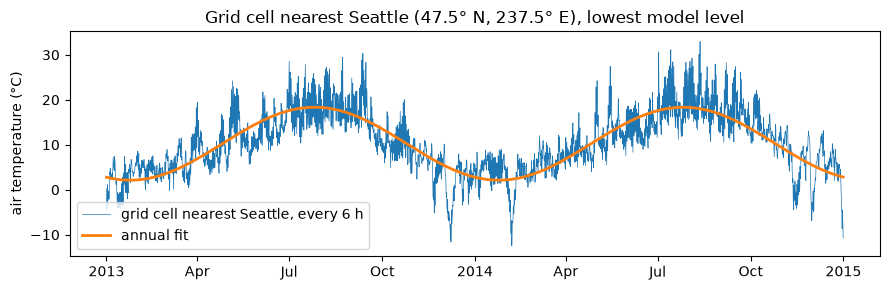

In [18]:
from scipy.optimize import curve_fit

sea = seattle_series_reference(ds)
t_days = (sea.time - sea.time[0]) / np.timedelta64(1, "D")


def annual(t, mean, amp, phase):
    return mean + amp * np.cos(2 * np.pi * (t - phase) / 365.25)


(p_mean, p_amp, p_phase), _ = curve_fit(annual, t_days.values, sea.values, p0=[10, 8, 200])
if p_amp < 0:                                  # same curve, written with a positive amplitude
    p_amp, p_phase = -p_amp, p_phase + 365.25 / 2
peak = pd.Timestamp(sea.time.values[0]) + pd.Timedelta(days=p_phase % 365.25)
print(f"mean {p_mean:.1f} C, amplitude {p_amp:.1f} C, warmest around {peak:%d %B}")

fig, ax = plt.subplots(figsize=(9, 3))
sea.plot(ax=ax, lw=0.5, label="grid cell nearest Seattle, every 6 h")
ax.plot(sea.time, annual(t_days.values, p_mean, p_amp, p_phase), lw=2, label="annual fit")
ax.set_ylabel("air temperature (°C)"); ax.set_xlabel("")
ax.set_title(f"Grid cell nearest Seattle ({float(sea.lat):.1f}° N, {float(sea.lon):.1f}° E), lowest model level")
ax.legend(); plt.tight_layout(); plt.show()

### E3. What does a tensor no longer know?

Deep-learning libraries take plain arrays. Converting a labeled grid to a tensor keeps the numbers and drops everything else.

In [19]:
import torch

tensor = torch.from_numpy(air_c.values.astype(np.float32))
print("tensor shape:", tuple(tensor.shape), " dtype:", tensor.dtype)
print("dimension names, coordinates, units: gone. Record them before converting:")
sidecar = {"dims": list(air_c.dims), "units": air_c.attrs["units"],
           "lat_first_last": [float(air_c.lat[0]), float(air_c.lat[-1])],
           "lon_first_last": [float(air_c.lon[0]), float(air_c.lon[-1])],
           "source_sha256": RAW_SHA256}
print(json.dumps(sidecar, indent=1))

back = xr.DataArray(tensor.numpy(), coords=air_c.coords, dims=sidecar["dims"], attrs=air_c.attrs)
print("round trip preserves the values to float32 precision:",
      bool(np.allclose(back.values, air_c.values, atol=1e-4)))

tensor shape: (2920, 25, 53)  dtype: torch.float32
dimension names, coordinates, units: gone. Record them before converting:
{
 "dims": [
  "time",
  "lat",
  "lon"
 ],
 "units": "degC",
 "lat_first_last": [
  75.0,
  15.0
 ],
 "lon_first_last": [
  200.0,
  330.0
 ],
 "source_sha256": "c606b89c35970a2983b914b76df4adbb409003ef34aa7cfd7f582e41f307482b"
}
round trip preserves the values to float32 precision: True


The order of dimensions in the tensor is the only record of which axis is time and which is latitude. A model trained on `(time, lat, lon)` and fed `(time, lon, lat)` runs without error.

## What to carry forward

| Habit | How you check it |
|---|---|
| Fix which bytes you used | A pinned checksum, and a raw file that is read-only |
| Know what one value means | Variable, level, grid spacing, time, observation versus model, written in the data card |
| Select by coordinate, safely | A tolerance of half a grid step, and the returned coordinates printed or tested |
| Keep metadata true | Units and ranges updated on a copy, a `history` entry, a fingerprint that reruns identically |
| Accept agent code on evidence | A check table that fails before the fix and passes after, and an entry in `AI_logs/` |

Section [2.6](2.6_resampling.ipynb) takes the same grid's time axis and asks what happens when you change its sampling.

## References

- Kalnay, E., et al. (1996). The NCEP/NCAR 40-year reanalysis project. *Bulletin of the American Meteorological Society*, 77, 437–471. [doi:10.1175/1520-0477(1996)077<0437:TNYRP>2.0.CO;2](https://doi.org/10.1175/1520-0477(1996)077%3C0437:TNYRP%3E2.0.CO;2)
- NOAA Physical Sciences Laboratory, [NCEP/NCAR Reanalysis 1](https://psl.noaa.gov/data/gridded/data.ncep.reanalysis.html).
- Xarray project, [pydata/xarray-data](https://github.com/pydata/xarray-data), file `air_temperature.nc` at commit `2baf0c2`.
- Natural Earth, [1:50m coastline](https://www.naturalearthdata.com/downloads/50m-physical-vectors/50m-coastline/), public domain.